# Klasifikasi I (SVM)

*Supervised learning* adalah metode *machine learning* yang belajar dari data yang **sudah memiliki label**. Berbeda dengan *clustering* (Modul 4–5) yang bekerja tanpa label, di sini model dilatih dari pasangan **fitur** (ciri-ciri yang diukur) dan **label** (jawaban yang benar), lalu dipakai untuk menebak label data baru. Jika label berupa kategori (mis. ganas/jinak), tugasnya disebut **klasifikasi**.

**Support Vector Machine (SVM)** mengklasifikasikan data dengan mencari satu batas pemisah terbaik di antara kelas-kelas yang ada:
- **Hyperplane**: batas pemisah (garis lurus pada 2 fitur, bidang datar pada 3 fitur, dan seterusnya).
- **Margin**: jarak antara hyperplane dengan titik terdekat dari tiap kelas — SVM memilih hyperplane dengan margin **paling lebar**.
- **Support vector**: titik-titik di tepi margin; hanya titik inilah yang menentukan posisi hyperplane.
- **Parameter C**: pengatur seberapa ketat pelanggaran margin dihukum (*soft margin*).
- **Kernel**: fungsi yang mengatur bentuk batas pemisah (*linear* = lurus, *RBF* = melengkung).

Model dievaluasi dengan **confusion matrix**, **precision**, **recall**, dan **F1-score** pada data uji.

---
## 1. Persiapan Environment & Import Library

### 1.1 Install Library

In [23]:
#pip install pandas numpy matplotlib scikit-learn

### 1.2 Import Library yang Dibutuhkan

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, classification_report

### 1.3 Mengenal Dataset Breast Cancer Wisconsin

Dataset bawaan scikit-learn: **569 data tumor payudara**, **30 fitur** hasil pengukuran sel tumor, dan label diagnosis **malignant** (ganas) atau **benign** (jinak).

In [25]:
data = load_breast_cancer() 
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

---
## 2. Eksplorasi Data

Pahami data seperti pada modul sebelumnya: tipe data, rentang nilai fitur, dan distribusi kelas.

### 2.1 Informasi Umum & Ringkasan Statistik

In [26]:
print(df.info())
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

### 2.2 Distribusi Kelas

target
1    357
0    212
Name: count, dtype: int64


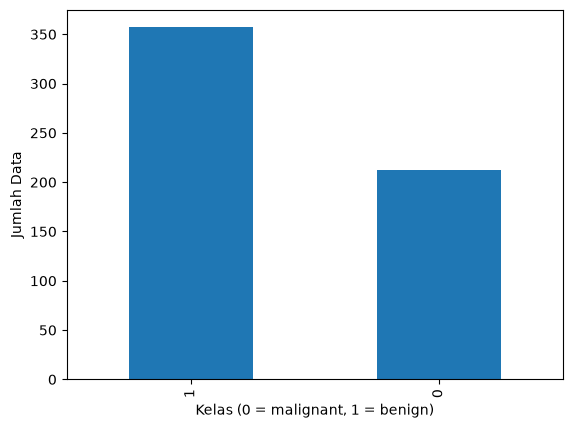

In [27]:
print(df['target'].value_counts())
df['target'].value_counts().plot(kind='bar')
plt.xlabel('Kelas (0 = malignant, 1 = benign)')
plt.ylabel('Jumlah Data')
plt.show()

---
## 3. Penanganan Data

Periksa nilai kosong dan data duplikat.

In [28]:
print(df.isnull().sum().sum()) 
print(df.duplicated().sum())

0
0


---
## 4. Membagi Data Latih dan Data Uji

Pisahkan fitur (`X`) dan label (`y`), lalu bagi menjadi 80% data latih dan 20% data uji (`stratify` dan `random_state=42`).

In [29]:
X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape) 

(455, 30) (114, 30)


---
## 5. Pemilihan Fitur

Pilih 10 fitur yang paling berkaitan dengan label berdasarkan korelasi — hanya dari data latih.

In [30]:
train = X_train.copy() 
train['target'] = y_train 
korelasi =  train.corr()['target'].drop('target').abs().sort_values(ascending=False) 

print(korelasi.head(10)) 
fitur_terpilih = korelasi.head(10).index 
X_train_sel = X_train[fitur_terpilih] 
X_test_sel = X_test[fitur_terpilih]

worst concave points    0.798176
worst perimeter         0.783376
mean concave points     0.779907
worst radius            0.776390
mean perimeter          0.745132
worst area              0.737965
mean radius             0.732224
mean area               0.713409
mean concavity          0.692052
worst concavity         0.668368
Name: target, dtype: float64


---
## 6. Scaling Data

Standardisasi fitur: `fit_transform` pada data latih, `transform` saja pada data uji.

In [31]:
scaler = StandardScaler() 
X_train_scaled = scaler.fit_transform(X_train_sel) 
X_test_scaled = scaler.transform(X_test_sel) 

---
## 7. Melatih Model SVM (Kernel Linear)

Latih `SVC(kernel='linear')` dengan data latih yang sudah di-scale, lalu lihat `n_support_`.

In [32]:
svm = SVC(kernel='linear') 
svm.fit(X_train_scaled, y_train) 
print(svm.n_support_) 

[30 31]


---
## 8. Prediksi dan Evaluasi

Prediksi data uji (`X_test_scaled`) lalu evaluasi dengan confusion matrix dan classification report.

### 8.1 Prediksi pada Data Uji

In [33]:
y_pred = svm.predict(X_test_scaled) 
hasil = pd.DataFrame({ 
    'Label sebenarnya': data.target_names[y_test[:5]], 
    'Prediksi': data.target_names[y_pred[:5]] 
})

print(hasil) 

  Label sebenarnya   Prediksi
0        malignant  malignant
1           benign     benign
2        malignant  malignant
3           benign     benign
4        malignant  malignant


### 8.2 Confusion Matrix

In [34]:
cm = confusion_matrix(y_test, y_pred) 
cm_df = pd.DataFrame( 
    cm, 
    index=['Sebenarnya malignant', 'Sebenarnya benign'], 
    columns=['Diprediksi malignant', 'Diprediksi benign'] 
) 

print(cm_df) 

                      Diprediksi malignant  Diprediksi benign
Sebenarnya malignant                    40                  2
Sebenarnya benign                        1                 71


### 8.3 Classification Report

In [35]:

print(classification_report(y_test, y_pred, target_names=data.target_names))

              precision    recall  f1-score   support

   malignant       0.98      0.95      0.96        42
      benign       0.97      0.99      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



---
## 9. Menggunakan Pipeline

Rangkai `StandardScaler` dan `SVC` dalam satu `Pipeline`, latih dengan `X_train_sel`, lalu bandingkan hasilnya dengan langkah manual.

In [36]:
model = Pipeline([ 
    ('scaler', StandardScaler()), 
    ('svm', SVC(kernel='linear')) 
]) 
model.fit(X_train_sel, y_train) 
y_pred_pipe = model.predict(X_test_sel) 
print('Hasil sama dengan tanpa Pipeline:', (y_pred == y_pred_pipe).all())

Hasil sama dengan tanpa Pipeline: True


---
## 10. Catatan Penting Praktikum

- SVM berbasis jarak, jadi **scaling wajib**.
- Urutan kerja yang benar: **split dulu**, baru pemilihan fitur dan scaling, dan keduanya hanya belajar dari **data latih**.
- Scaler: `fit_transform` pada data latih, `transform` saja pada data uji.
- `stratify=y` menjaga proporsi kelas di data latih dan data uji.
- Jangan mengandalkan accuracy saja — baca precision, recall, dan F1 **per kelas**.
- Baca confusion matrix berdasarkan nama baris dan kolomnya (label 1 = kelas positif menurut scikit-learn).
- `C` kecil = margin lebar & aturan longgar; `C` besar = margin sempit & aturan ketat.

---
## 11. Latihan

**Studi Kasus: Prediksi Pembelian Produk dari Iklan Media Sosial**

Link dataset: https://github.com/codejack-CR/Social-Network-Ads (file `Social_Network_Ads.csv`; salinan lokal tersedia di folder Pertemuan 6 sebagai cadangan).

Sebuah perusahaan ingin memasang iklan produk di media sosial. Agar biaya iklan lebih efisien, iklan hanya ingin ditampilkan kepada pengguna yang diperkirakan akan membeli produk tersebut. Dataset berisi: `User ID`, `Gender`, `Age`, `EstimatedSalary`, dan `Purchased` (0 = tidak membeli, 1 = membeli).

Dengan menggunakan algoritma SVM, lakukan analisis berikut:
1. Baca dataset Social Network Ads ke dalam Python dan tampilkan 5 baris pertama.
2. Lakukan eksplorasi data (EDA): tampilkan informasi data, ringkasan statistik, dan distribusi kelas `Purchased`. Jelaskan mengapa scaling diperlukan pada data ini berdasarkan rentang nilai `Age` dan `EstimatedSalary`.
3. Lakukan penanganan data: periksa nilai kosong dan data duplikat, serta ubah kolom `Gender` menjadi angka.
4. Pisahkan fitur dan label, lalu bagi data menjadi 80% data latih dan 20% data uji dengan `stratify` dan `random_state=42`.
5. Lakukan pemilihan fitur (*feature selection*) menggunakan data latih saja. Tentukan fitur yang relevan untuk memprediksi `Purchased`, dan jelaskan alasan pemilihannya.
6. Bangun model SVM dengan kernel linear menggunakan `Pipeline` yang berisi `StandardScaler` dan `SVC`, lalu latih model menggunakan data latih.
7. Prediksi data uji, lalu tampilkan confusion matrix dan `classification_report` dengan nama kelas "tidak membeli" dan "membeli".
8. Interpretasikan hasil evaluasi:
   - a. Berapa pengguna yang sebenarnya membeli tetapi diprediksi tidak membeli, dan berapa pengguna yang sebaliknya?
   - b. Bagi perusahaan yang ingin menjangkau calon pembeli, metrik mana yang lebih penting, precision atau recall pada kelas "membeli"? Jelaskan alasannya.
   - c. Bandingkan nilai accuracy dengan recall pada kelas "membeli". Apa yang dapat disimpulkan?
9. Buat rekomendasi strategi penayangan iklan berdasarkan hasil evaluasi tersebut.

In [39]:
df = pd.read_csv('Social_Network_Ads.csv')

display(df.head(5))

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [40]:
print(df.info())
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   User ID          400 non-null    int64
 1   Gender           400 non-null    str  
 2   Age              400 non-null    int64
 3   EstimatedSalary  400 non-null    int64
 4   Purchased        400 non-null    int64
dtypes: int64(4), str(1)
memory usage: 15.8 KB
None
            User ID         Age  EstimatedSalary   Purchased
count  4.000000e+02  400.000000       400.000000  400.000000
mean   1.569154e+07   37.655000     69742.500000    0.357500
std    7.165832e+04   10.482877     34096.960282    0.479864
min    1.556669e+07   18.000000     15000.000000    0.000000
25%    1.562676e+07   29.750000     43000.000000    0.000000
50%    1.569434e+07   37.000000     70000.000000    0.000000
75%    1.575036e+07   46.000000     88000.000000    1.000000
max    1.581524e+07   60.000000    150000.000000    1.00000

Purchased
0    257
1    143
Name: count, dtype: int64


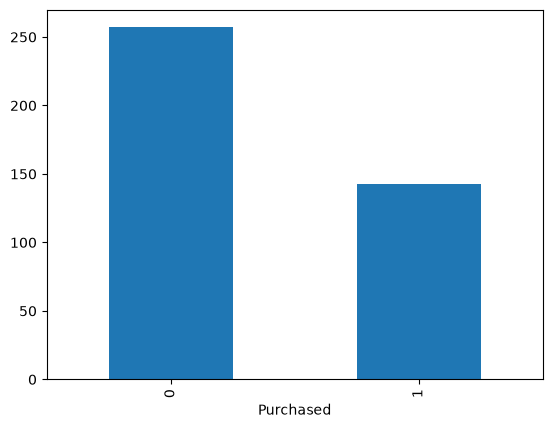

In [41]:
# distribusi kelas
print(df['Purchased'].value_counts())
df['Purchased'].value_counts().plot(kind='bar')
plt.show()

In [54]:
# penanganan data
print(df.isnull().sum().sum()) 
print(df.duplicated().sum())

# ubah kolom gender menjadi angka
df['Gender'] = df['Gender'].map({'Female': 0, 'Male': 1})
display(df)

0
0


,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,1,19,19000,0
1,15810944,1,35,20000,0
2,15668575,0,26,43000,0
3,15603246,0,27,57000,0
4,15804002,1,19,76000,0
...,...,...,...,...,...
395,15691863,0,46,41000,1
396,15706071,1,51,23000,1
397,15654296,0,50,20000,1
398,15755018,1,36,33000,0


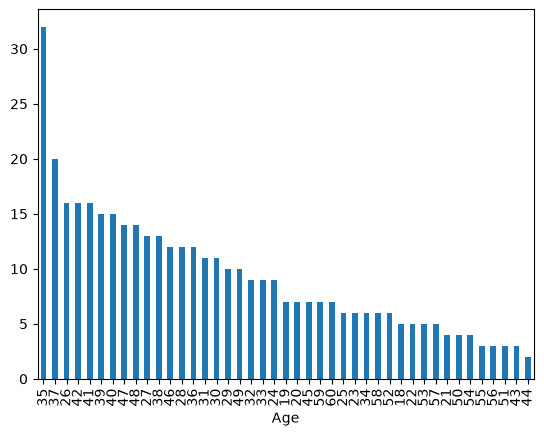

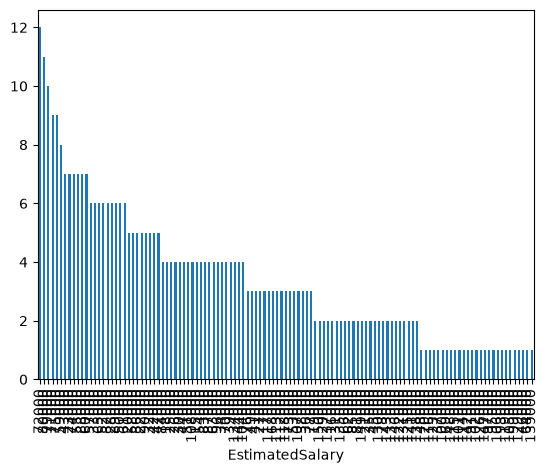

In [51]:
# distribusi kolom Age
df['Age'].value_counts().plot(kind='bar')
plt.show()

# distribusi kolom EstimatedSalary
df['EstimatedSalary'].value_counts().plot(kind='bar')
plt.show()

In [57]:
# membago data latih dan data uji
X = df.drop(columns='Purchased')
y = df['Purchased']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)

(320, 4) (80, 4)


In [ ]:
# feature selection
train = X_train.copy() 
train['Purchased'] = y_train 
korelasi = train.corr()['Purchased'].drop('Purchased').abs().sort_values(ascending=False)

print(korelasi.head(10)) 
fitur_terpilih = ['']
X_train_sel = X_train[fitur_terpilih] 
X_test_sel = X_test[fitur_terpilih]

Age                0.618531
EstimatedSalary    0.408334
Gender             0.031017
User ID            0.001817
Name: Purchased, dtype: float64
